In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
from possessions import zone
from markov import matrice_transition
from ligue import charger_ligue, actions_toutes_equipes, sequences_toutes_equipes
from epoques import SAISONS, charger_toutes_saisons, resume_par_match, indicateurs, bootstrap, valeurs_saison

seq = charger_toutes_saisons(dossier="../data")     # long la première fois
m = resume_par_match(seq)
print(len(seq), "possessions,", len(m), "matchs")

48381 possessions, 524 matchs6/17match 17/32match 17/34match 21/34


In [2]:
tab = m.groupby("season_id").apply(indicateurs)
tab.insert(0, "saison", [SAISONS[s][0] for s in tab.index])
tab.insert(1, "coach", [SAISONS[s][1] for s in tab.index])
tab = tab.sort_values("saison")
tab

,saison,coach,matchs,taux_but,perte_par_action,longueur
season_id,,,,,,
37,2004/05,Rijkaard,7.0,0.019174,0.097479,10.061947
38,2005/06,Rijkaard,17.0,0.019231,0.105933,9.258413
39,2006/07,Rijkaard,26.0,0.016883,0.088290,11.135061
40,2007/08,Rijkaard,27.0,0.017616,0.090742,10.826087
41,2008/09,Guardiola,31.0,0.027254,0.087936,11.061911
21,2009/10,Guardiola,35.0,0.023256,0.082269,11.872524
22,2010/11,Guardiola,33.0,0.024738,0.065327,14.928957
23,2011/12,Guardiola,37.0,0.027177,0.066474,14.634717
24,2012/13,Vilanova,32.0,0.029182,0.063683,15.244656


In [3]:
seq_L = sequences_toutes_equipes(actions_toutes_equipes(charger_ligue(27, dossier="../data")))
P_L, _ = matrice_transition(seq_L)

valeurs = []
for sid in tab.index:
    V = valeurs_saison(seq[seq.season_id == sid], P_L)
    valeurs.append([V[zone(10, 40)], V[zone(60, 40)], V[zone(116, 40)]])
tab[["V_surface", "V_rond", "V_but"]] = valeurs
tab.round(4)

,saison,coach,matchs,taux_but,perte_par_action,longueur,V_surface,V_rond,V_but
season_id,,,,,,,,,
37,2004/05,Rijkaard,7.0,0.0192,0.0975,10.0619,0.0095,0.0151,0.2708
38,2005/06,Rijkaard,17.0,0.0192,0.1059,9.2584,0.0093,0.0138,0.2992
39,2006/07,Rijkaard,26.0,0.0169,0.0883,11.1351,0.0103,0.0143,0.3168
40,2007/08,Rijkaard,27.0,0.0176,0.0907,10.8261,0.0078,0.0145,0.3327
41,2008/09,Guardiola,31.0,0.0273,0.0879,11.0619,0.0139,0.0214,0.4738
21,2009/10,Guardiola,35.0,0.0233,0.0823,11.8725,0.0103,0.0191,0.3585
22,2010/11,Guardiola,33.0,0.0247,0.0653,14.9290,0.0126,0.0219,0.5653
23,2011/12,Guardiola,37.0,0.0272,0.0665,14.6347,0.0143,0.0228,0.4837
24,2012/13,Vilanova,32.0,0.0292,0.0637,15.2447,0.0133,0.0266,0.4223


In [4]:
def difference(s1, s2, col, n=2000):
    """IC à 95 % de (indicateur saison s1 − indicateur saison s2)."""
    rng = np.random.default_rng(0)
    A, B = m[m.season_id == s1], m[m.season_id == s2]
    d = []
    for _ in range(n):
        x = indicateurs(A.iloc[rng.integers(0, len(A), len(A))])
        y = indicateurs(B.iloc[rng.integers(0, len(B), len(B))])
        d.append(x[col] - y[col])
    bas, haut = np.quantile(d, [0.025, 0.975])
    return round(bas, 4), round(haut, 4)

print("Taux de but, 2015/16 − 2020/21 :", difference(27, 90, "taux_but"))
print("Taux de but, 2008/09 − 2020/21 :", difference(41, 90, "taux_but"))
print("Perte/action, 2008/09 − 2020/21 :", difference(41, 90, "perte_par_action"))
print("Perte/action, 2008/09 − 2015/16 :", difference(41, 27, "perte_par_action"))

Taux de but, 2015/16 − 2020/21 : (np.float64(-0.0029), np.float64(0.0146))
Taux de but, 2008/09 − 2020/21 : (np.float64(-0.0036), np.float64(0.0132))
Perte/action, 2008/09 − 2020/21 : (np.float64(0.0169), np.float64(0.0307))
Perte/action, 2008/09 − 2015/16 : (np.float64(0.0085), np.float64(0.0237))


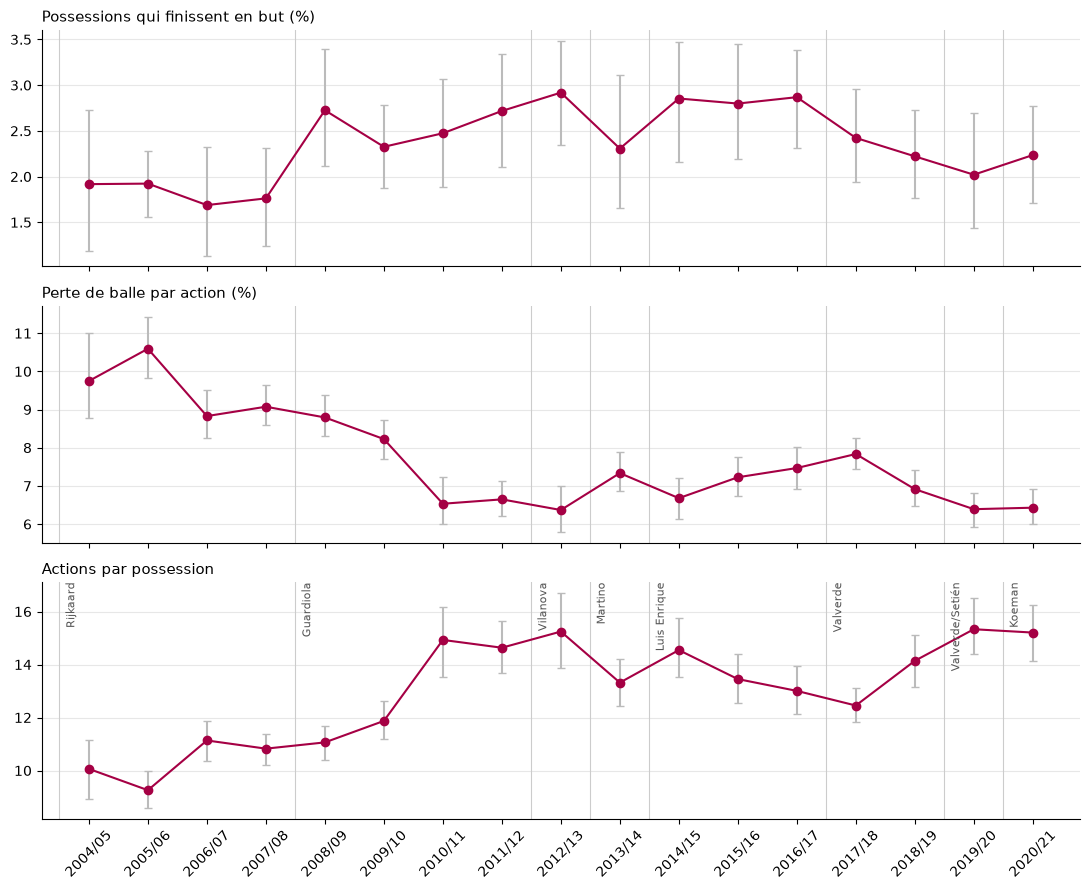

In [5]:
import matplotlib.pyplot as plt

lignes = []
for sid, (saison, coach) in SAISONS.items():
    ms = m[m.season_id == sid]
    ind = indicateurs(ms)
    bas, haut = bootstrap(ms, n=500)
    lignes.append({"saison": saison, "coach": coach, **ind,
                   **{k + "_bas": bas[k] for k in ind.index},
                   **{k + "_haut": haut[k] for k in ind.index}})
t = pd.DataFrame(lignes).sort_values("saison").reset_index(drop=True)

fig, axs = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
x = np.arange(len(t))
panneaux = [("taux_but", "Possessions qui finissent en but (%)", 100),
            ("perte_par_action", "Perte de balle par action (%)", 100),
            ("longueur", "Actions par possession", 1)]
for ax, (col, titre, echelle) in zip(axs, panneaux):
    y = t[col] * echelle
    erreurs = [(t[col] - t[col + "_bas"]) * echelle, (t[col + "_haut"] - t[col]) * echelle]
    ax.errorbar(x, y, yerr=erreurs, fmt="o-", color="#a50044", ecolor="#bbbbbb", capsize=3)
    ax.set_title(titre, loc="left", fontsize=11)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
debuts = t.groupby("coach", sort=False).apply(lambda g: g.index.min())
for coach, i in debuts.items():
    for ax in axs:
        ax.axvline(i - 0.5, color="#cccccc", lw=0.8)
    axs[2].text(i - 0.4, axs[2].get_ylim()[1], coach, fontsize=8, va="top", rotation=90, color="#555555")
axs[-1].set_xticks(x)
axs[-1].set_xticklabels(t.saison, rotation=45)
fig.tight_layout()
fig.savefig("../figures/epoques.png", dpi=150)